# 10 — Random catalogs

A clustering measurement needs, for each data catalog, a random catalog with the same angular footprint and
the same redshift distribution but no clustering. `cat.make_random(...)` makes it for a catalog built with
`base.make_catalog(...)` (notebook 09).

- **Sky positions** are uniform inside the footprint of the lightcone. The footprint is exact: the lightcone
  is made of sky patches, rectangles in the angles θ and φ listed in `lc_cores-decomposition.txt`, and each
  galaxy carries its patch number (`lc_patch`).
- **Redshifts** are drawn, with replacement, from the redshifts of the data catalog.
- A contaminated catalog gives **three data catalogs**, each with its own randoms:

| `which` | data catalog | `id_outcome` |
|---|---|---|
| `"all"` | galaxies and interlopers | 1, 2, 3 |
| `"galaxies"` | galaxies with a correct redshift | 1 (multi-line), 2 (single-line, correct) |
| `"interlopers"` | galaxies with a wrong redshift | 3 (single-line, misidentified) |

Randoms N times as numerous as the data are N catalogs of the size of the data, one file each.

In [1]:
import os
os.environ.setdefault("JAX_PLATFORMS", "cpu")   # diffsky imports JAX; avoid CUDA probing on login nodes
import warnings
warnings.filterwarnings("ignore", message="Version checking")

import numpy as np
import matplotlib.pyplot as plt
import opencosmo as oc

from romanmock import plotting
plotting.use_style()

CATALOG = "/global/cfs/cdirs/m4943/Simulations/sdss_feniks_hizels_260710_09_07_2026"
WORK = os.path.join(os.environ.get("PSCRATCH", "/tmp"), "romanmock_demo")   # outputs of the tutorials
os.makedirs(WORK, exist_ok=True)

## The footprint

In [2]:
from romanmock import BaseCatalog, Catalog

base = BaseCatalog(os.path.join(WORK, "two_step", "base"))
footprint = base.footprint          # built once from the mock, then cached in the base directory
print(footprint)
print("patches:", footprint.patches.tolist())
print(f"area: {footprint.area_deg2:.2f} deg2 (exact)   {base.area_deg2:.2f} deg2 (estimate from the galaxies, used for dN/dz)")

<PatchFootprint: 60 patches, 2062.65 deg2, 57.85 < dec < 75.16>
patches: [20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33, 34, 35, 36, 37, 38, 39, 40, 41, 42, 43, 44, 45, 46, 47, 48, 49, 50, 51, 52, 53, 54, 55, 56, 57, 58, 59, 60, 61, 62, 63, 64, 65, 66, 67, 68, 69, 70, 71, 72, 73, 74, 75, 76, 77, 78, 79]
area: 2062.65 deg2 (exact)   2063.00 deg2 (estimate from the galaxies, used for dN/dz)


## A contaminated catalog and its three data catalogs

An Hα sample at 1.0 < z < 1.9. `id_outcome` must be among the columns (it is by default): it tells the
galaxies with a correct redshift from the interlopers.

In [3]:
confusion = {
    "Ha":        {"OIII_5007": 0.2},
    "OIII_5007": {"Ha": 0.2},
    "SIII_9532": {"Ha": 0.2},
    "Hb":        {"OIII_5007": 0.2},
}
cat = base.make_catalog(flux_limit=1.5e-16, secondary_flux_limit=8.0e-17, confusion=confusion,
                        lines=["Ha"], z_range=(1.0, 1.9), seed=2026)

[romanmock] 66 slices of base, 8 worker(s)


[romanmock] 44,929,655 of 64,556,046 base galaxies detected; 23,051,555 in the catalog


[romanmock] lines inside 10000 - 19300 A for redshift_assigned in 1 - 1.9 (lightcone: z_rsd 0.01 - 4.06)
  line        rest [A]    redshift      observed [A]       detected   identified    brightest    mistaken  interlopers
  Ha            6564.7  1.000 - 1.900   13129 - 19038    22,917,719   22,917,719   22,913,712           0      133,836
  Hb            4862.8  1.056 - 1.900   10000 - 14102     3,593,496    3,593,496            0           0            0   not in `lines`
  OIII_5007     5008.3  1.000 - 1.900   10017 - 14524    18,083,024   18,004,823            0      78,201            0   not in `lines`
  OIII_4959     4960.4  1.016 - 1.900   10000 - 14385     2,018,202    2,018,202            0           0            0   not in `lines`
  OII_3727      3728.6  1.682 - 1.900   10000 - 10813       175,909      175,909            0           0            0   not in `lines`
  SIII_9532     9533.4  1.000 - 1.024   19067 - 19300       800,070      744,435        4,007      55,635        

In [4]:
data = {which: cat.subset(which) for which in ("all", "galaxies", "interlopers")}
for which, d in data.items():
    z_true, z = d["redshift_rsd"], d["redshift_assigned"]
    print(f"{which:<12s} {len(d):>11,} galaxies   true redshift {z_true.min():.3f} - {z_true.max():.3f}   "
          f"assigned redshift {z.min():.3f} - {z.max():.3f}")

all           23,051,555 galaxies   true redshift 0.377 - 2.801   assigned redshift 1.000 - 1.900
galaxies      22,917,719 galaxies   true redshift 1.000 - 1.900   assigned redshift 1.000 - 1.900
interlopers      133,836 galaxies   true redshift 0.377 - 2.801   assigned redshift 1.000 - 1.900


## Randoms in memory

One call for the three kinds; `which="all"` alone returns just the list. Each random catalog has the size of
its data catalog and the columns `ra`, `dec` and the redshift column of the redshift cut.

In [5]:
%%time
randoms = cat.make_random(which=["all", "galaxies", "interlopers"], n_times=2, seed=7)

[romanmock] randoms for 'all': 2 x 23,051,555 points, uniform inside 2062.6 deg2, redshift_assigned drawn from the data


[romanmock] randoms for 'galaxies': 2 x 22,917,719 points, uniform inside 2062.6 deg2, redshift_assigned drawn from the data


[romanmock] randoms for 'interlopers': 2 x 133,836 points, uniform inside 2062.6 deg2, redshift_assigned drawn from the data


CPU times: user 14.3 s, sys: 7.11 s, total: 21.4 s
Wall time: 21.5 s


In [6]:
from astropy.table import Table

ran = randoms["all"][0]
print(ran)
print("settings['random']:", ran.settings["random"])
t = Table({c: ran[c][:6] for c in ran.columns})
for c in t.colnames:
    t[c].format = ".5f"
t

<Catalog: 23,051,555 galaxies, 3 columns ['ra', 'dec', 'redshift_assigned']; F > 1.50e-16 (other lines > 8.00e-17); lines ['Ha'], redshift_assigned in (1.0, 1.9)>
settings['random']: {'which': 'all', 'index': 0, 'seed': 7, 'n_data': 23051555}


ra,dec,redshift_assigned
float64,float64,float64
253.90497,62.38673,1.85357
203.42384,59.14040,1.10857
106.88823,64.52462,1.16036
206.87409,65.52019,1.18635
311.22421,66.74956,1.43762
197.25382,72.77508,1.62095


## On the sky

Number of objects per square degree in cells of right ascension and declination, for the data and for one
random catalog. The outlines are the 60 patches of the footprint. The data show large-scale structure, the
randoms only shot noise; both stop at the same edges.

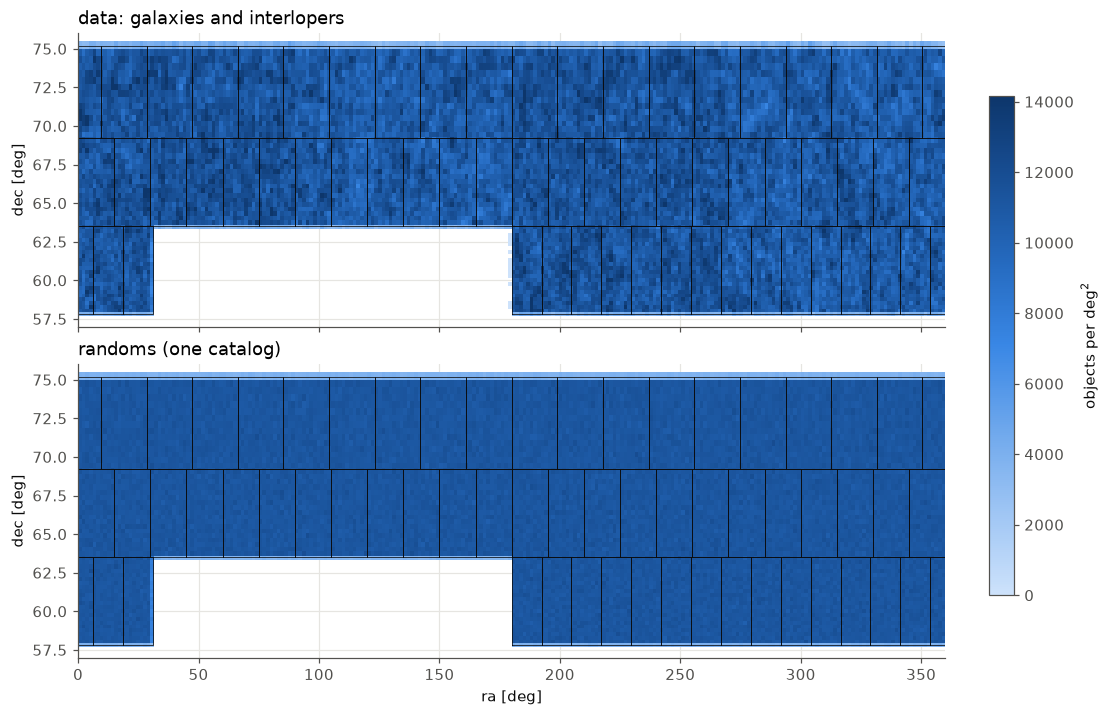

In [7]:
ra_edges = np.linspace(0.0, 360.0, 241)
sin_edges = np.linspace(np.sin(np.radians(57.0)), np.sin(np.radians(76.0)), 61)      # equal-area cells
cell = np.degrees(1.0) ** 2 * np.radians(np.diff(ra_edges))[:, None] * np.diff(sin_edges)[None, :]
dec_edges = np.degrees(np.arcsin(sin_edges))

def density(c):
    return np.histogram2d(c["ra"], np.sin(np.radians(c["dec"])), bins=(ra_edges, sin_edges))[0] / cell

maps = {"data: galaxies and interlopers": density(cat), "randoms (one catalog)": density(ran)}
vmax = np.percentile(maps["data: galaxies and interlopers"], 99.5)
fig, axes = plt.subplots(2, 1, figsize=(10, 6.4), sharex=True, constrained_layout=True)
for ax, (title, m) in zip(axes, maps.items()):
    im = ax.pcolormesh(ra_edges, dec_edges, np.where(m > 0, m, np.nan).T, cmap=plotting.sequential_cmap(), vmin=0, vmax=vmax,
                       rasterized=True)
    for lo, hi, d_lo, d_hi in footprint.rectangles():
        ax.plot([lo, hi, hi, lo, lo], [d_lo, d_lo, d_hi, d_hi, d_lo], color=plotting.TEXT_PRIMARY, lw=0.5)
    ax.set_title(title, loc="left")
    ax.set_ylabel("dec [deg]")
axes[-1].set_xlabel("ra [deg]")
fig.colorbar(im, ax=axes, label="objects per deg$^2$", shrink=0.8)
plt.show()

In [8]:
inside = footprint.contains(cat["ra"], cat["dec"])
print(f"randoms inside the footprint: {footprint.contains(ran['ra'], ran['dec']).mean():.6f}")
print(f"data inside the footprint:    {inside.mean():.6f}   ({np.sum(~inside):,} galaxies outside: satellites of haloes at the edge)")

d, r = density(cat) * cell, density(ran) * cell
centre_ra, centre_dec = np.meshgrid(0.5 * (ra_edges[1:] + ra_edges[:-1]), 0.5 * (dec_edges[1:] + dec_edges[:-1]), indexing="ij")
corners = [footprint.contains(a[:, None], b[None, :]) for a in (ra_edges[:-1], ra_edges[1:]) for b in (dec_edges[:-1], dec_edges[1:])]
interior = np.all(corners, axis=0) & footprint.contains(centre_ra, centre_dec)      # cells with the four corners inside
edge = (r > 0) & ~interior
print(f"data / randoms in the {interior.sum():,} cells inside the footprint: {d[interior].sum() / r[interior].sum():.4f}")
print(f"data / randoms in the {edge.sum():,} cells on its edge:            {d[edge].sum() / r[edge].sum():.4f}")

randoms inside the footprint: 1.000000
data inside the footprint:    0.999941   (1,368 galaxies outside: satellites of haloes at the edge)


data / randoms in the 10,760 cells inside the footprint: 0.9999
data / randoms in the 502 cells on its edge:            1.0047


If the galaxies outside the footprint matter for your measurement, remove them with
`cat = cat[footprint.contains(cat["ra"], cat["dec"])]` before making the randoms.

## In redshift

Each random catalog follows the redshift distribution of its own data catalog. The interlopers have a
distribution of their own: the Hα sample contains [O III] 5007 emitters from z = 1.94–2.80 and [S III] 9532
emitters from z = 0.38–1.00, placed at the redshift their line would have as Hα. The [S III] interlopers
drop at an assigned redshift of 1.21: above z = 0.52 their own Hα line is inside the grism, which makes most of
them multi-line galaxies with a correct redshift. The [O III] interlopers start at an assigned redshift of 1.24.

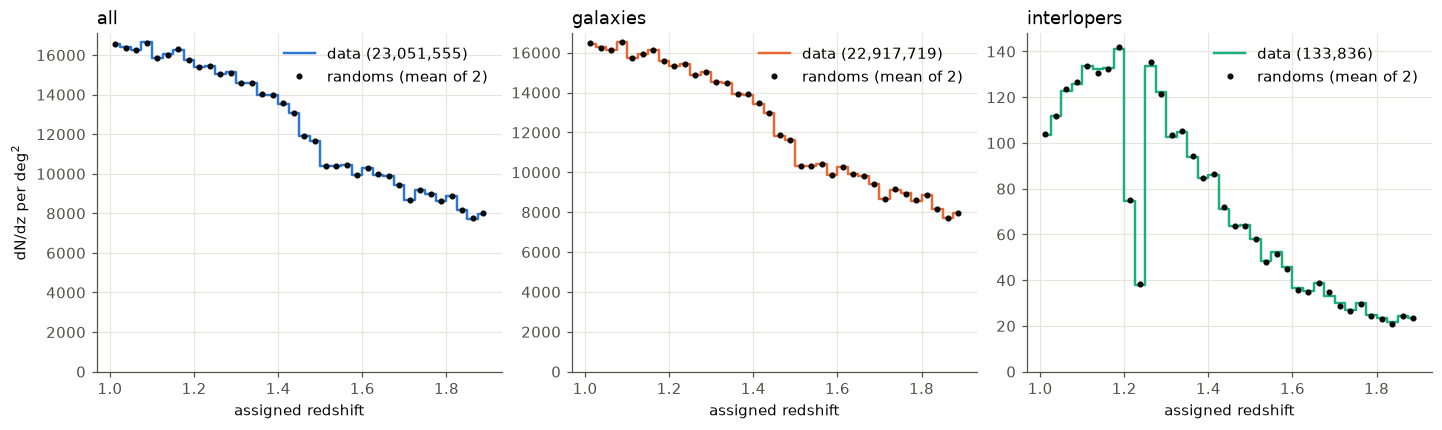

In [9]:
z_col = cat.settings["z_column"]
edges = np.linspace(1.0, 1.9, 37)
zc = 0.5 * (edges[1:] + edges[:-1])
fig, axes = plt.subplots(1, 3, figsize=(13, 3.8), constrained_layout=True)
for ax, which, color in zip(axes, data, plotting.CATEGORICAL):
    d = data[which].dndz(edges, z_col)
    r = np.mean([x.dndz(edges, z_col) for x in randoms[which]], axis=0)
    ax.step(zc, d, where="mid", color=color, lw=1.6, label=f"data ({len(data[which]):,})")
    ax.plot(zc, r, "o", ms=3, color=plotting.TEXT_PRIMARY, label=f"randoms (mean of {len(randoms[which])})")
    ax.set_title(which, loc="left")
    ax.set_xlabel("assigned redshift")
    ax.set_ylim(0, None)
    ax.legend(frameon=False)
axes[0].set_ylabel("dN/dz per deg$^2$")
plt.show()

## Randoms on disk: N files

With `write_to` the randoms are written one after the other instead of being returned, so that a large
multiple of the data never sits in memory at once. `name.hdf5` gives `name_<which>_00.hdf5`,
`name_<which>_01.hdf5`, ... (without `<which>` when a single kind is asked for).

In [10]:
del randoms
out = os.path.join(WORK, "two_step", "randoms", "halpha_z1p0_1p9.hdf5")
cat.write(out)                                                                   # the data catalog, next to its randoms
files = cat.make_random(which=["all", "galaxies", "interlopers"], n_times=2, seed=7, write_to=out)
for which, paths in files.items():
    print(which, [f"{p.name} ({os.path.getsize(p) / 1e6:.0f} MB)" for p in paths])

[romanmock] randoms for 'all': 2 x 23,051,555 points, uniform inside 2062.6 deg2, redshift_assigned drawn from the data


[romanmock]   /pscratch/sd/w/willlake/romanmock_demo/two_step/randoms/halpha_z1p0_1p9_all_00.hdf5


[romanmock]   /pscratch/sd/w/willlake/romanmock_demo/two_step/randoms/halpha_z1p0_1p9_all_01.hdf5


[romanmock] randoms for 'galaxies': 2 x 22,917,719 points, uniform inside 2062.6 deg2, redshift_assigned drawn from the data


[romanmock]   /pscratch/sd/w/willlake/romanmock_demo/two_step/randoms/halpha_z1p0_1p9_galaxies_00.hdf5


[romanmock]   /pscratch/sd/w/willlake/romanmock_demo/two_step/randoms/halpha_z1p0_1p9_galaxies_01.hdf5


[romanmock] randoms for 'interlopers': 2 x 133,836 points, uniform inside 2062.6 deg2, redshift_assigned drawn from the data


[romanmock]   /pscratch/sd/w/willlake/romanmock_demo/two_step/randoms/halpha_z1p0_1p9_interlopers_00.hdf5


[romanmock]   /pscratch/sd/w/willlake/romanmock_demo/two_step/randoms/halpha_z1p0_1p9_interlopers_01.hdf5


all ['halpha_z1p0_1p9_all_00.hdf5 (553 MB)', 'halpha_z1p0_1p9_all_01.hdf5 (553 MB)']
galaxies ['halpha_z1p0_1p9_galaxies_00.hdf5 (550 MB)', 'halpha_z1p0_1p9_galaxies_01.hdf5 (550 MB)']
interlopers ['halpha_z1p0_1p9_interlopers_00.hdf5 (3 MB)', 'halpha_z1p0_1p9_interlopers_01.hdf5 (3 MB)']


In [11]:
back = Catalog.read(files["interlopers"][1])
print(back)
print(back.settings["random"], "| footprint area", round(back.area_deg2, 2), "deg2")

<Catalog: 133,836 galaxies, 3 columns ['ra', 'dec', 'redshift_assigned']; F > 1.50e-16 (other lines > 8.00e-17); lines ['Ha'], redshift_assigned in (1.0, 1.9)>
{'which': 'interlopers', 'index': 1, 'seed': 7, 'n_data': 133836} | footprint area 2062.65 deg2


Random catalog `k` of a kind depends on `(seed, which, k)` only. It can be made again on its own, and more
can be added later with `first=` without remaking the existing ones.

In [12]:
again = cat.make_random(which="interlopers", n_times=1, first=1, seed=7, verbose=False)[0]
print("catalog 1 made again equals the file:", all(np.array_equal(again[c], back[c]) for c in back.columns))

more = cat.make_random(which="interlopers", n_times=2, first=2, seed=7, write_to=out.replace(".hdf5", "_interlopers.hdf5"))
print([p.name for p in more])

catalog 1 made again equals the file: True


[romanmock] randoms for 'interlopers': 2 x 133,836 points, uniform inside 2062.6 deg2, redshift_assigned drawn from the data


[romanmock]   /pscratch/sd/w/willlake/romanmock_demo/two_step/randoms/halpha_z1p0_1p9_interlopers_02.hdf5


[romanmock]   /pscratch/sd/w/willlake/romanmock_demo/two_step/randoms/halpha_z1p0_1p9_interlopers_03.hdf5


['halpha_z1p0_1p9_interlopers_02.hdf5', 'halpha_z1p0_1p9_interlopers_03.hdf5']


## Cuts on the sky

A cut on `ra` or `dec` made with `cuts=` in `make_catalog` is applied to the randoms as well.

In [13]:
part = base.make_catalog(flux_limit=1.5e-16, secondary_flux_limit=8.0e-17, confusion=confusion, lines=["Ha"],
                         z_range=(1.0, 1.9), cuts={"ra": (200.0, 300.0), "dec": (60.0, 70.0)}, seed=2026, verbose=False)
r = part.make_random(n_times=1)[0]
print(f"data:    {len(part):,}  ra {part['ra'].min():.2f} - {part['ra'].max():.2f}  dec {part['dec'].min():.2f} - {part['dec'].max():.2f}")
print(f"randoms: {len(r):,}  ra {r['ra'].min():.2f} - {r['ra'].max():.2f}  dec {r['dec'].min():.2f} - {r['dec'].max():.2f}")

[romanmock] randoms for 'all': 1 x 4,751,282 points, uniform inside 2062.6 deg2 and {'ra': (200.0, 300.0), 'dec': (60.0, 70.0)}, redshift_assigned drawn from the data


data:    4,751,282  ra 200.00 - 300.00  dec 60.00 - 70.00
randoms: 4,751,282  ra 200.00 - 300.00  dec 60.00 - 70.00


## From the command line

```bash
romanmock catalog /path/to/base -o halpha.hdf5 --flux-limit 1.5e-16 --secondary-flux-limit 8e-17 \
          --confusion my_confusion.yaml --lines Ha --z-range 1.0 1.9
romanmock random halpha.hdf5 -n 10 --which all galaxies interlopers -o randoms/halpha.hdf5
```

## Notes

- Redshifts drawn from the data carry the radial structure of the data into the randoms, which slightly
  suppresses the clustering of the modes along the line of sight. The effect is small for 2063 deg².
- The randoms of `"all"` are not the sum of the randoms of `"galaxies"` and `"interlopers"`: each set is drawn
  on its own, from the redshifts of its own data catalog.